**Name:** Timothy Mayabi

**Email**: usafiri2018@gmail.com

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


# Data Overview

In [6]:
# Load the customer churn dataset
file_path = "../data/customer_churn.xlsx"
df = pd.read_excel(
    file_path,
    sheet_name='Data for DSBA'
)

#Inspect the dataset
print("Dataset shape:", df.shape)

display(df.head())
df.info()

Dataset shape: (11260, 19)


,AccountID,Churn,Tenure,City_Tier,CC_Contacted_LY,Payment,Gender,Service_Score,Account_user_count,account_segment,CC_Agent_Score,Marital_Status,rev_per_month,Complain_ly,rev_growth_yoy,coupon_used_for_payment,Day_Since_CC_connect,cashback,Login_device
0,20000,1,4,3.0,6.0,Debit Card,Female,3.0,3,Super,2.0,Single,9,1.0,11,1,5,159.93,Mobile
1,20001,1,0,1.0,8.0,UPI,Male,3.0,4,Regular Plus,3.0,Single,7,1.0,15,0,0,120.9,Mobile
2,20002,1,0,1.0,30.0,Debit Card,Male,2.0,4,Regular Plus,3.0,Single,6,1.0,14,0,3,NaN,Mobile
3,20003,1,0,3.0,15.0,Debit Card,Male,2.0,4,Super,5.0,Single,8,0.0,23,0,3,134.07,Mobile
4,20004,1,0,1.0,12.0,Credit Card,Male,2.0,3,Regular Plus,5.0,Single,3,0.0,11,1,3,129.6,Mobile


<class 'pandas.DataFrame'>
RangeIndex: 11260 entries, 0 to 11259
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   AccountID                11260 non-null  int64  
 1   Churn                    11260 non-null  int64  
 2   Tenure                   11158 non-null  object 
 3   City_Tier                11148 non-null  float64
 4   CC_Contacted_LY          11158 non-null  float64
 5   Payment                  11151 non-null  str    
 6   Gender                   11152 non-null  str    
 7   Service_Score            11162 non-null  float64
 8   Account_user_count       11148 non-null  object 
 9   account_segment          11163 non-null  str    
 10  CC_Agent_Score           11144 non-null  float64
 11  Marital_Status           11048 non-null  str    
 12  rev_per_month            11158 non-null  object 
 13  Complain_ly              10903 non-null  float64
 14  rev_growth_yoy           11260 no

## Descriptive Statistics

This section examines the distribution and summary statistics of numerical and categorical variables to understand the characteristics of customer accounts

In [7]:
# Numerical variables
display(df.describe())

# Categorical variables
display(df.describe(include=['object', 'str']))


,AccountID,Churn,City_Tier,CC_Contacted_LY,Service_Score,CC_Agent_Score,Complain_ly
count,11260.00000,11260.000000,11148.000000,11158.000000,11162.000000,11144.000000,10903.000000
mean,25629.50000,0.168384,1.653929,17.867091,2.902526,3.066493,0.285334
std,3250.62635,0.374223,0.915015,8.853269,0.725584,1.379772,0.451594
min,20000.00000,0.000000,1.000000,4.000000,0.000000,1.000000,0.000000
25%,22814.75000,0.000000,1.000000,11.000000,2.000000,2.000000,0.000000
50%,25629.50000,0.000000,1.000000,16.000000,3.000000,3.000000,0.000000
75%,28444.25000,0.000000,3.000000,23.000000,3.000000,4.000000,1.000000
max,31259.00000,1.000000,3.000000,132.000000,5.000000,5.000000,1.000000


,Tenure,Payment,Gender,Account_user_count,account_segment,Marital_Status,rev_per_month,rev_growth_yoy,coupon_used_for_payment,Day_Since_CC_connect,cashback,Login_device
count,11158,11151,11152,11148,11163,11048,11158,11260,11260,10903,10789.00,11039
unique,38,5,4,7,7,3,59,20,20,24,5693.00,3
top,1,Debit Card,Male,4,Super,Married,3,14,1,3,155.62,Mobile
freq,1351,4587,6328,4569,4062,5860,1746,1524,4373,1816,10.00,7482


## Investigate incorrectly classified variables

In this section, we identify the values preventing expected numerical columns from being interpreted correctly.

In [8]:
# Columns expected to contain numerical values
numeric_columns = [
    "Tenure",
    "Account_user_count",
    "rev_per_month",
    "rev_growth_yoy",
    "coupon_used_for_payment",
    "Day_Since_CC_connect",
    "cashback"
]

for col in numeric_columns:
    converted = pd.to_numeric(df[col], errors='coerce')

    invalid_values = df.loc[
        df[col].notna() & converted.isna(), col
    ].unique()

    print(f"\n{col}")
    print("Current dtype:", df[col].dtype)
    print("Invalid values:", invalid_values)


Tenure
Current dtype: object
Invalid values: ['#']

Account_user_count
Current dtype: object
Invalid values: ['@']

rev_per_month
Current dtype: object
Invalid values: ['+']

rev_growth_yoy
Current dtype: object
Invalid values: ['$']

coupon_used_for_payment
Current dtype: object
Invalid values: ['#' '$' '*']

Day_Since_CC_connect
Current dtype: object
Invalid values: ['$']

cashback
Current dtype: object
Invalid values: ['$']


## Missing value analysis

This will show us which variables have missing values and the proportion of affected records

In [9]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)
display(missing_summary)

,Missing Count,Missing Percentage
cashback,471,4.18
Complain_ly,357,3.17
Day_Since_CC_connect,357,3.17
Login_device,221,1.96
Marital_Status,212,1.88
CC_Agent_Score,116,1.03
City_Tier,112,0.99
Account_user_count,112,0.99
Payment,109,0.97
Gender,108,0.96


## Check duplicate records

In [10]:
print ("Duplicate rows: ", df.duplicated().sum())

print("Duplicated Account Ids:", df["AccountID"].duplicated().sum())

Duplicate rows:  0
Duplicated Account Ids: 0


### Initial Data Quality Observations

The dataset contains 11,260 customer account records and 19 variables, including the target variable `Churn`.

**Key observations:**

1. The overall churn rate is approximately 16.84%, indicating that churned accounts represent a minority of the dataset. This class imbalance will need to be considered during model development.
2. Customer care interactions vary considerably across accounts, with some recording up to 132 contacts in the previous year.
3. Average service satisfaction and customer care satisfaction scores are approximately 2.90 and 3.07, respectively.
4. Several numerical variables have been incorrectly classified as categorical because they contain special characters such as `#`, `@`, `$`, `+`, and `*`.
5. Missing values exist across multiple variables, with `cashback`, `Complain_ly`, and `Day_Since_CC_connect` having the highest initially observed missing percentages.
6. No duplicate records or account identifiers were identified.

**Conclusion:** The dataset requires additional cleaning, particularly numerical type conversion, missing-value treatment, and categorical consistency checks, before reliable exploratory analysis can be performed.

# Data Cleaning and Preprocessing

## Correct invalid numerical values and data types

In [12]:
# Create a working copy to preserve the original dataset

df_clean = df.copy()

# Numerical columns requiring correction

numeric_columns = [
    "Tenure",
    "Account_user_count",
    "rev_per_month",
    "rev_growth_yoy",
    "coupon_used_for_payment",
    "Day_Since_CC_connect",
    "cashback"
]

# Convert invalid values to NaN and correct data types
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')


# Verify corrected data types
print("Corrected numerical data types:")
print(df_clean[numeric_columns].dtypes)

# Missing values after numerical conversion
missing_after_conversion = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_after_conversion = (
    missing_after_conversion[missing_after_conversion["Missing Count"] > 0].sort_values(by="Missing Percentage", ascending=False)
)

display(missing_after_conversion)

Corrected numerical data types:
Tenure                     float64
Account_user_count         float64
rev_per_month              float64
rev_growth_yoy             float64
coupon_used_for_payment    float64
Day_Since_CC_connect       float64
cashback                   float64
dtype: object


,Missing Count,Missing Percentage
rev_per_month,791,7.02
cashback,473,4.20
Account_user_count,444,3.94
Day_Since_CC_connect,358,3.18
Complain_ly,357,3.17
Login_device,221,1.96
Tenure,218,1.94
Marital_Status,212,1.88
CC_Agent_Score,116,1.03
City_Tier,112,0.99


## Numerical Variable Distribution Analysis

Before imputing missing values, the distributions of numerical variables are examined to identify skewness and potential outliers. These characteristics will inform the selection of appropriate imputation methods.

,count,mean,std,min,25%,50%,75%,max
Tenure,11042.0,11.03,12.88,0.0,2.00,9.00,16.00,99.0
Account_user_count,10816.0,3.69,1.02,1.0,3.00,4.00,4.00,6.0
rev_per_month,10469.0,6.36,11.91,1.0,3.00,5.00,7.00,140.0
rev_growth_yoy,11257.0,16.19,3.76,4.0,13.00,15.00,19.00,28.0
coupon_used_for_payment,11257.0,1.79,1.97,0.0,1.00,1.00,2.00,16.0
Day_Since_CC_connect,10902.0,4.63,3.70,0.0,2.00,3.00,8.00,47.0
cashback,10787.0,196.24,178.66,0.0,147.21,165.25,200.01,1997.0
CC_Contacted_LY,11158.0,17.87,8.85,4.0,11.00,16.00,23.00,132.0
Service_Score,11162.0,2.90,0.73,0.0,2.00,3.00,3.00,5.0
CC_Agent_Score,11144.0,3.07,1.38,1.0,2.00,3.00,4.00,5.0


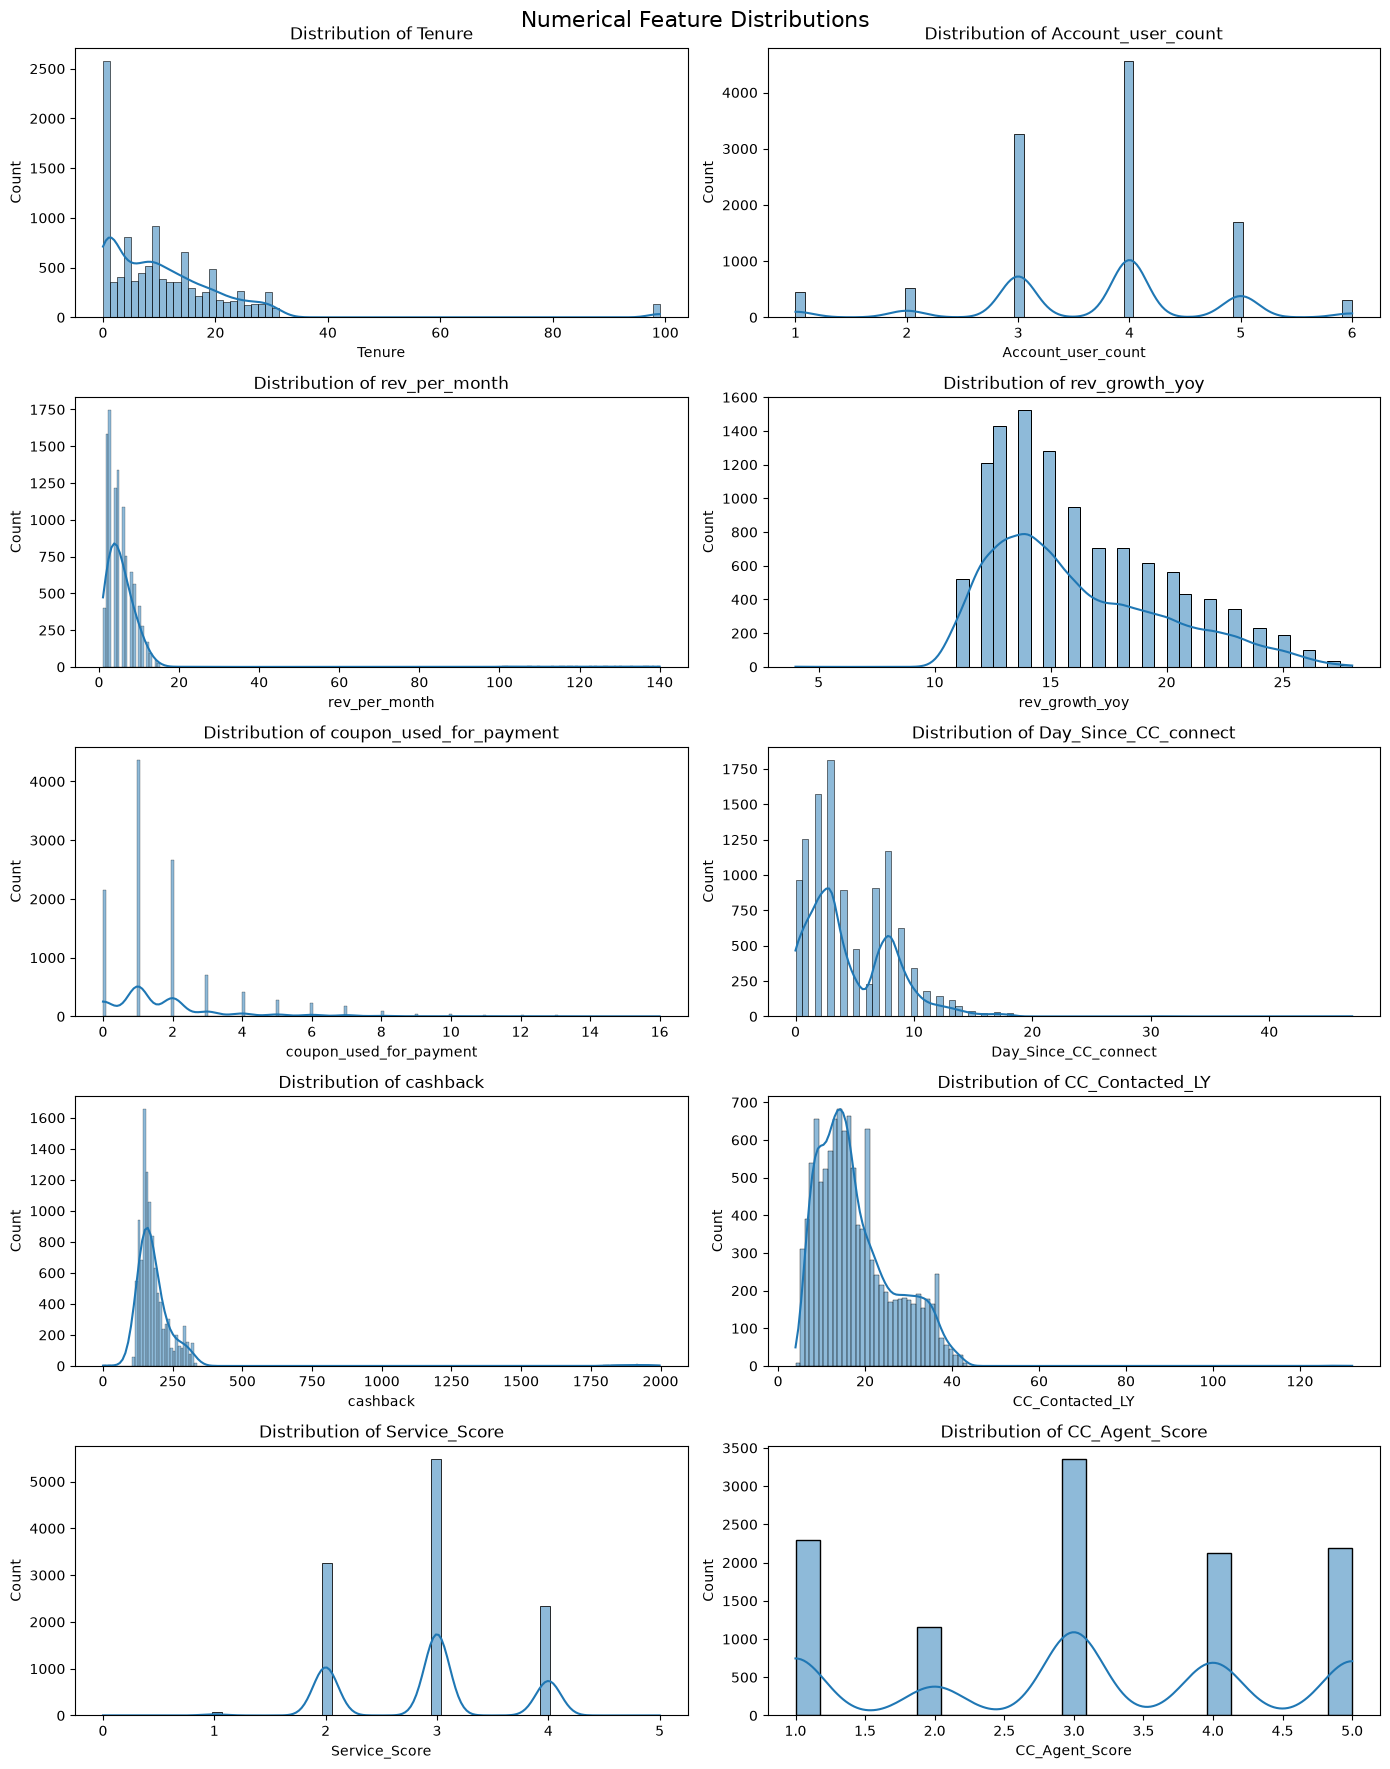

In [14]:
# Examine numerical distributions before imputation

numeric_features = [
    "Tenure",
    "Account_user_count",
    "rev_per_month",
    "rev_growth_yoy",
    "coupon_used_for_payment",
    "Day_Since_CC_connect",
    "cashback",
    "CC_Contacted_LY",
    "Service_Score",
    "CC_Agent_Score"
]

# Summary statistics
display(df_clean[numeric_features].describe().T.round(2))

# Distribution plots for numerical features
fig, axes = plt.subplots(5, 2, figsize=(14, 18))
fig.suptitle("Numerical Feature Distributions", fontsize=16)

for ax, col in zip(axes.flatten(), numeric_features):
    sns.histplot(
        df_clean[col].dropna(),
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

### Numerical Distribution Analysis - Key Observations

The numerical distribution analysis revealed the following:

- **Skewed variables:** Monthly revenue, cashback, tenure, coupon usage, and days since customer care contact exhibit positive skewness.
- **Potential outliers:** Extreme values were observed in monthly revenue (140), cashback (1,997), tenure (99), and customer care contacts (132). These require further investigation before treatment.
- **Account composition:** Most accounts contain three or four users, indicating that account-level churn can affect multiple customers.
- **Customer satisfaction:** Service satisfaction scores are concentrated around 2–4, while customer care satisfaction scores span 1-5.
- **Imputation considerations:** Median imputation is a reasonable candidate for skewed numerical variables, while mode imputation may be appropriate for discrete account user counts.

**Conclusion:** The dataset contains skewed distributions and potentially influential observations. Outlier treatment should consider business relevance, particularly for revenue-generating accounts, rather than removing extreme values indiscriminately.

## Investigate outliers before imputation
Investigating the unusual values in Tenure, rev_per_month, cashback and CC_Contacted_LY

In [16]:
# Investigate potentially extreme values
outlier_checks = {
    "Tenure": 90,
    "rev_per_month": 50,
    "cashback": 500,
    "CC_Contacted_LY": 60
}

outlier_results = []

for col, threshold in outlier_checks.items():
    extreme = df_clean[df_clean[col] > threshold]

    outlier_results.append({
        "Variable": col,
        "Threshold": threshold,
        "Accounts": len(extreme),
        "Percentage (%)": round(
            len(extreme) / len(df_clean) * 100, 2
        ),
        "Min Extreme": extreme[col].min(),
        "Max Extreme": extreme[col].max(),
        "Churn Rate (%)": round(
            extreme["Churn"].mean() * 100, 2
        ) if len(extreme) > 0 else 0
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Variable,Threshold,Accounts,Percentage (%),Min Extreme,Max Extreme,Churn Rate (%)
0,Tenure,90,131,1.16,99.0,99.0,18.32
1,rev_per_month,50,105,0.93,100.0,140.0,21.90
2,cashback,500,108,0.96,1800.0,1997.0,20.37
3,CC_Contacted_LY,60,4,0.04,126.0,132.0,0.00


In [17]:
# Identify suspicious observations
suspicious = pd.DataFrame({
    "Tenure_99": df_clean["Tenure"] == 99,
    "High_Revenue": df_clean["rev_per_month"] >= 100,
    "High_Cashback": df_clean["cashback"] >= 1800,
    "High_CC_Contacts": df_clean["CC_Contacted_LY"] > 60
})

# Count suspicious conditions per account
suspicious["Total_Flags"] = suspicious.sum(axis=1)

# Summarize overlap
display(
    suspicious["Total_Flags"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Flags")
    .reset_index(name="Accounts")
)

# Check overlap between suspicious variables
display(
    suspicious.drop(columns="Total_Flags")
    .astype(int)
    .T
    .dot(suspicious.drop(columns="Total_Flags").astype(int))
)

,Number of Flags,Accounts
0,0,10912
1,1,348


,Tenure_99,High_Revenue,High_Cashback,High_CC_Contacts
Tenure_99,131,0,0,0
High_Revenue,0,105,0,0
High_Cashback,0,0,108,0
High_CC_Contacts,0,0,0,4


### Outlier Investigation - Findings

An investigation of four potentially anomalous numerical variables identified 348 accounts (3.09% of the dataset) with extreme values.

The analysis revealed that none of these accounts had overlapping outlier flags. Each affected account exhibited an extreme value in only one of the investigated variables.

The unusual observations included tenure of 99, monthly revenue between 100 and 140, cashback between 1,800 and 1,997, and customer care contact counts between 126 and 132.

Although these observations are unusual, there is insufficient evidence to classify them definitively as errors. Consequently, they will be retained during exploratory analysis, with further investigation and sensitivity testing planned before predictive modeling.

**Business implication:** Removing extreme revenue observations without verification could exclude commercially valuable accounts and distort the development of targeted retention strategies.

## Check whether missing values are associated with churn
Before imputing missing values, we need to determine whether missingness differs between churned and retained accounts.
For example, if monthly revenue is missing more frequently among churned accounts, that missingness could itself carry predictive information.


In [19]:
# Analyze missingness by churn status
missing_by_churn = []

for col in df_clean.columns.drop(["AccountID", "Churn"]):
    missing_by_churn.append({
        "Variable": col,
        "Retained Missing (%)": round(
            df_clean[df_clean["Churn"] == 0][col].isna().mean() * 100, 2
        ),
        "Churned Missing (%)": round(
            df_clean[df_clean["Churn"] == 1][col].isna().mean() * 100, 2
        )
    })

missing_by_churn_df = pd.DataFrame(missing_by_churn)

missing_by_churn_df["Difference (pp)"] = (
    missing_by_churn_df["Churned Missing (%)"] - missing_by_churn_df["Retained Missing (%)"]
).round(2)

display(
    missing_by_churn_df.sort_values(
        "Difference (pp)",
        key=abs,
        ascending=False
    )
)

,Variable,Retained Missing (%),Churned Missing (%),Difference (pp)
10,rev_per_month,7.16,6.38,-0.78
0,Tenure,1.82,2.53,0.71
6,Account_user_count,4.04,3.48,-0.56
15,cashback,4.14,4.48,0.34
16,Login_device,1.91,2.22,0.31
4,Gender,0.92,1.16,0.24
14,Day_Since_CC_connect,3.14,3.38,0.24
9,Marital_Status,1.92,1.69,-0.23
3,Payment,0.93,1.16,0.23
8,CC_Agent_Score,1.00,1.16,0.16


## Missing Value Treatment
Missing values were handled according to variable characteristics. Median imputation was applied to numerical variables because several distributions were skewed. Mode imputation was applied to account user counts, while missing categorical values were assigned an explicit Unknown category. These transformations create an analysis-ready dataset for exploratory data analysis.

In [20]:
# Preserve the converted dataset
df_eda = df_clean.copy()

# Numerical variables
numeric_features = [
    "Tenure",
    "Account_user_count",
    "rev_per_month",
    "rev_growth_yoy",
    "coupon_used_for_payment",
    "Day_Since_CC_connect",
    "cashback",
    "CC_Contacted_LY",
    "Service_Score",
    "CC_Agent_Score",
    "City_Tier",
    "Complain_ly"
]

# Impute numerical variables using the median
for col in numeric_features:
    if col == "Account_user_count":
        df_eda[col] = df_eda[col].fillna(
            df_eda[col].mode().iloc[0]
        )
    else:
        df_eda[col] = df_eda[col].fillna(
            df_eda[col].median()
        )

# Identify categorical variables
categorical_features = df_eda.select_dtypes(
    include=["object", "str", "category"]
).columns

# Replace missing categorical values
for col in categorical_features:
    df_eda[col] = df_eda[col].fillna("Unknown")

# Verify remaining missing values
print("Total missing values:", df_eda.isnull().sum().sum())

print("Dataset shape:", df_eda.shape)

Total missing values: 0
Dataset shape: (11260, 19)


## Check categorical consistency

Its important to inspect the categories for inconsistencies.

In [21]:
categorical_columns = [
    "Gender",
    "Payment",
    "account_segment",
    "Marital_Status",
    "Login_device"
]

for col in categorical_columns:
    print(f"\n{'=' * 40}")
    print(f"{col}")
    print(df_eda[col].value_counts(dropna=False))


Gender
Gender
Male       6328
Female     4178
M           376
F           270
Unknown     108
Name: count, dtype: int64

Payment
Payment
Debit Card          4587
Credit Card         3511
E wallet            1217
Cash on Delivery    1014
UPI                  822
Unknown              109
Name: count, dtype: int64

account_segment
account_segment
Super           4062
Regular Plus    3862
HNI             1639
Super Plus       771
Regular          520
Regular +        262
Unknown           97
Super +           47
Name: count, dtype: int64

Marital_Status
Marital_Status
Married     5860
Single      3520
Divorced    1668
Unknown      212
Name: count, dtype: int64

Login_device
Login_device
Mobile      7482
Computer    3018
&&&&         539
Unknown      221
Name: count, dtype: int64


In [22]:
# Standardize gender categories
df_eda["Gender"] = df_eda["Gender"].replace({
    "M": "Male",
    "F": "Female"
})

print("Gender distribution after standardization:")
display(df_eda["Gender"].value_counts())

Gender distribution after standardization:


Gender
Male       6704
Female     4448
Unknown     108
Name: count, dtype: int64

In [23]:
# Inspect categorical values in a readable format
columns_to_check = [
    "account_segment",
    "Marital_Status",
    "Login_device"
]

for col in columns_to_check:
    summary = (
        df_eda[col]
        .value_counts(dropna=False)
        .reset_index()
    )

    summary.columns = [col, "Count"]

    print(f"\n{col}")
    display(summary)


account_segment


,account_segment,Count
0,Super,4062
1,Regular Plus,3862
2,HNI,1639
3,Super Plus,771
4,Regular,520
5,Regular +,262
6,Unknown,97
7,Super +,47



Marital_Status


,Marital_Status,Count
0,Married,5860
1,Single,3520
2,Divorced,1668
3,Unknown,212



Login_device


,Login_device,Count
0,Mobile,7482
1,Computer,3018
2,&&&&,539
3,Unknown,221


## Categorical Data Standardization
Categorical variables were examined for inconsistent labels and invalid values. Equivalent account segment labels were standardized, and invalid login device values were assigned to the Unknown category. Missing categorical values had previously been labeled Unknown to preserve the original account records.

In [24]:
# Standardize account segments
df_eda["account_segment"] = df_eda["account_segment"].replace({
    "Regular +": "Regular Plus",
    "Super +": "Super Plus"
})

# Replace invalid login device category
df_eda["Login_device"] = df_eda["Login_device"].replace({
    "&&&&": "Unknown"
})

# Verify cleaned categories
for col in ["account_segment", "Login_device"]:
    print(f"\n{col}")
    display(df_eda[col].value_counts().to_frame("Count"))


account_segment


,Count
account_segment,
Regular Plus,4124
Super,4062
HNI,1639
Super Plus,818
Regular,520
Unknown,97



Login_device


,Count
Login_device,
Mobile,7482
Computer,3018
Unknown,760


In [25]:
print("Dataset shape:", df_eda.shape)
print("Missing values:", df_eda.isnull().sum().sum())
print("Duplicate accounts:", df_eda["AccountID"].duplicated().sum())

display(df_eda.head())

Dataset shape: (11260, 19)
Missing values: 0
Duplicate accounts: 0


,AccountID,Churn,Tenure,City_Tier,CC_Contacted_LY,Payment,Gender,Service_Score,Account_user_count,account_segment,CC_Agent_Score,Marital_Status,rev_per_month,Complain_ly,rev_growth_yoy,coupon_used_for_payment,Day_Since_CC_connect,cashback,Login_device
0,20000,1,4.0,3.0,6.0,Debit Card,Female,3.0,3.0,Super,2.0,Single,9.0,1.0,11.0,1.0,5.0,159.93,Mobile
1,20001,1,0.0,1.0,8.0,UPI,Male,3.0,4.0,Regular Plus,3.0,Single,7.0,1.0,15.0,0.0,0.0,120.90,Mobile
2,20002,1,0.0,1.0,30.0,Debit Card,Male,2.0,4.0,Regular Plus,3.0,Single,6.0,1.0,14.0,0.0,3.0,165.25,Mobile
3,20003,1,0.0,3.0,15.0,Debit Card,Male,2.0,4.0,Super,5.0,Single,8.0,0.0,23.0,0.0,3.0,134.07,Mobile
4,20004,1,0.0,1.0,12.0,Credit Card,Male,2.0,3.0,Regular Plus,5.0,Single,3.0,0.0,11.0,1.0,3.0,129.60,Mobile


### Categorical Data Cleaning - Key Observations

Categorical data inspection identified inconsistent gender labels, account segment naming variations, and invalid login device values.

The following standardization rules were applied:

- Gender categories `M` and `F` were standardized to `Male` and `Female`.
- Account segment labels `Regular +` and `Super +` were standardized to `Regular Plus` and `Super Plus`.
- Invalid login device entries represented by `&&&&` were reclassified as `Unknown`.
- Existing valid payment and marital status categories were preserved.

These transformations improved categorical consistency without removing account records.

**Conclusion:** The cleaned dataset is suitable for exploratory analysis. Potential numerical outliers have been retained pending further investigation, and preprocessing decisions have been documented for reproducibility.